# Prédiction de la charge de chauffage des bâtiments

Mini-projet 03 — jeu Energy Efficiency (UCI). Cible unique : Y1. Les huit variables X1–X8 sont les entrées ; Y2 est exclue. Les mesures proviennent de bâtiments simulés.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from src.train import ROOT, load_data, FEATURES, LABELS
data = load_data()
print('Dimensions :', data.shape)
print('Valeurs manquantes :', int(data.isna().sum().sum()))
display(data[FEATURES + ['Y1']].describe().round(2))

Dimensions : (768, 10)
Valeurs manquantes : 0


,X1,X2,X3,X4,X5,X6,X7,X8,Y1
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.76,671.71,318.50,176.60,5.25,3.50,0.23,2.81,22.31
std,0.11,88.09,43.63,45.17,1.75,1.12,0.13,1.55,10.09
min,0.62,514.50,245.00,110.25,3.50,2.00,0.00,0.00,6.01
25%,0.68,606.38,294.00,140.88,3.50,2.75,0.10,1.75,12.99
50%,0.75,673.75,318.50,183.75,5.25,3.50,0.25,3.00,18.95
75%,0.83,741.12,343.00,220.50,7.00,4.25,0.40,4.00,31.67
max,0.98,808.50,416.50,220.50,7.00,5.00,0.40,5.00,43.10


## Exploration

Y1 est la charge de chauffage. Les graphiques suivants montrent sa distribution et son lien avec plusieurs caractéristiques. Cette exploration est descriptive.

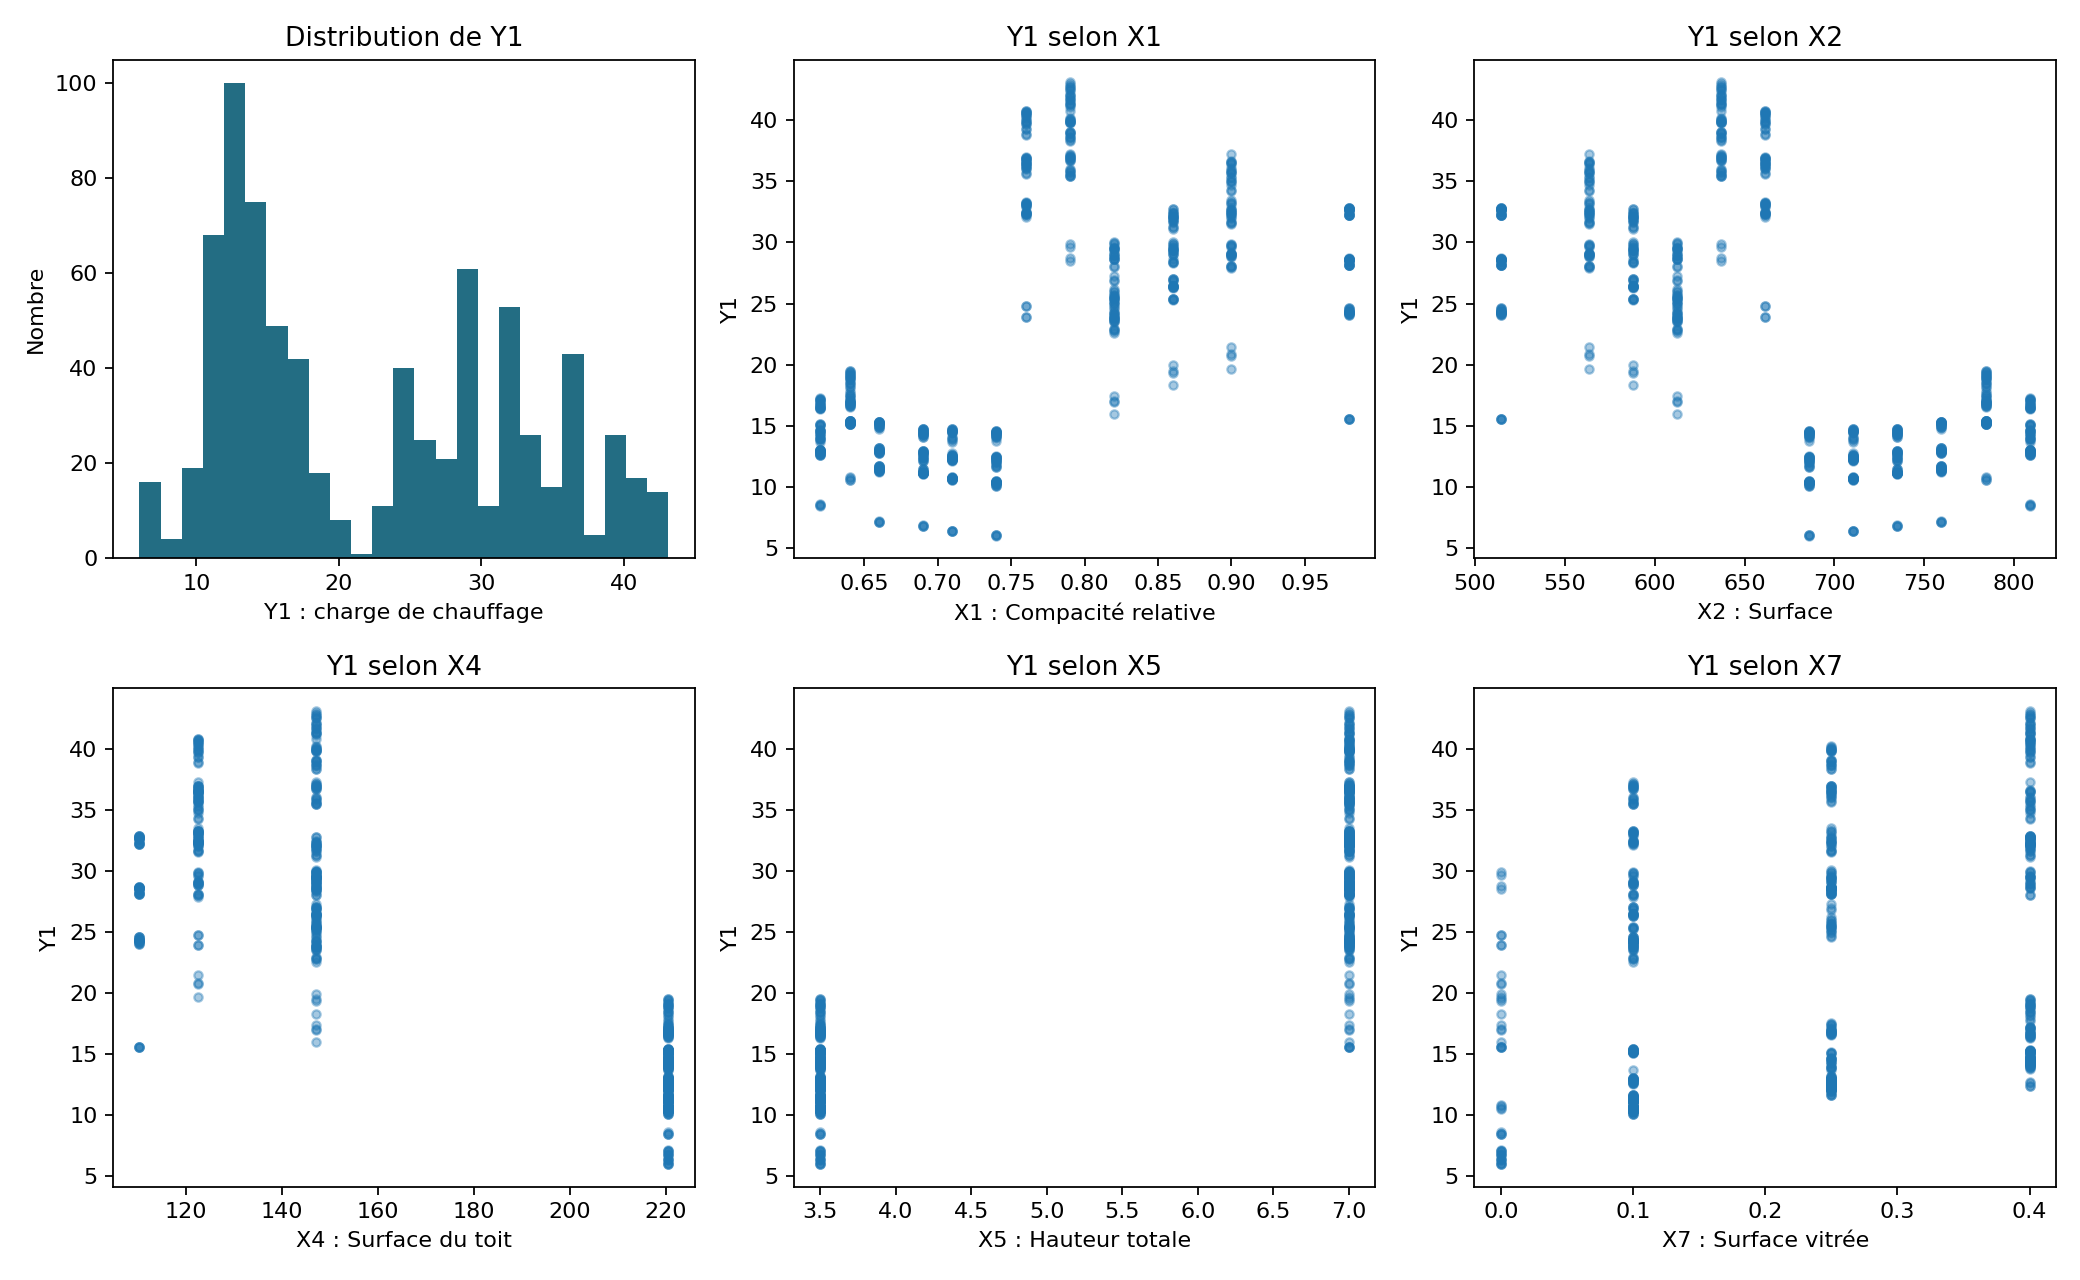

In [2]:
display(Image(filename=str(ROOT/'figures'/'01_exploration.png')))

## Protocole

Séparation aléatoire 80/20 avec `random_state=42`. Les 614 observations d’entraînement servent à la validation croisée à cinq plis et au choix des paramètres selon le RMSE. Les 154 observations de test ne servent qu’à l’évaluation finale. Les transformations sont apprises dans chaque pli grâce aux pipelines.

In [3]:
from src.train import main
scores = main()

Régression linéaire: CV_RMSE=2.828, test_RMSE=2.872, R2=0.921; {}


Ridge: CV_RMSE=2.828, test_RMSE=2.874, R2=0.921; {'model__alpha': 0.1}


KNN: CV_RMSE=1.559, test_RMSE=1.671, R2=0.973; {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'uniform'}


Arbre de décision: CV_RMSE=0.579, test_RMSE=0.531, R2=0.997; {'model__max_depth': 8, 'model__min_samples_leaf': 2}


Random Forest: CV_RMSE=0.535, test_RMSE=0.536, R2=0.997; {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


Entraînement: 614 ; test: 154 ; modèle sélectionné par CV: Random Forest


## Comparaison des cinq modèles

MAE : erreur absolue moyenne ; MSE : moyenne des erreurs au carré ; RMSE : racine du MSE ; R² : part de la variabilité de Y1 expliquée par le modèle. Plus MAE/MSE/RMSE sont faibles, mieux c’est ; plus R² est proche de 1, mieux c’est.

,Model,CV_RMSE,MAE,MSE,RMSE,R2
0,Random Forest,0.535,0.371,0.287,0.536,0.997
1,Arbre de décision,0.579,0.353,0.282,0.531,0.997
2,KNN,1.559,1.118,2.793,1.671,0.973
3,Ridge,2.828,2.061,8.257,2.874,0.921
4,Régression linéaire,2.828,2.059,8.250,2.872,0.921


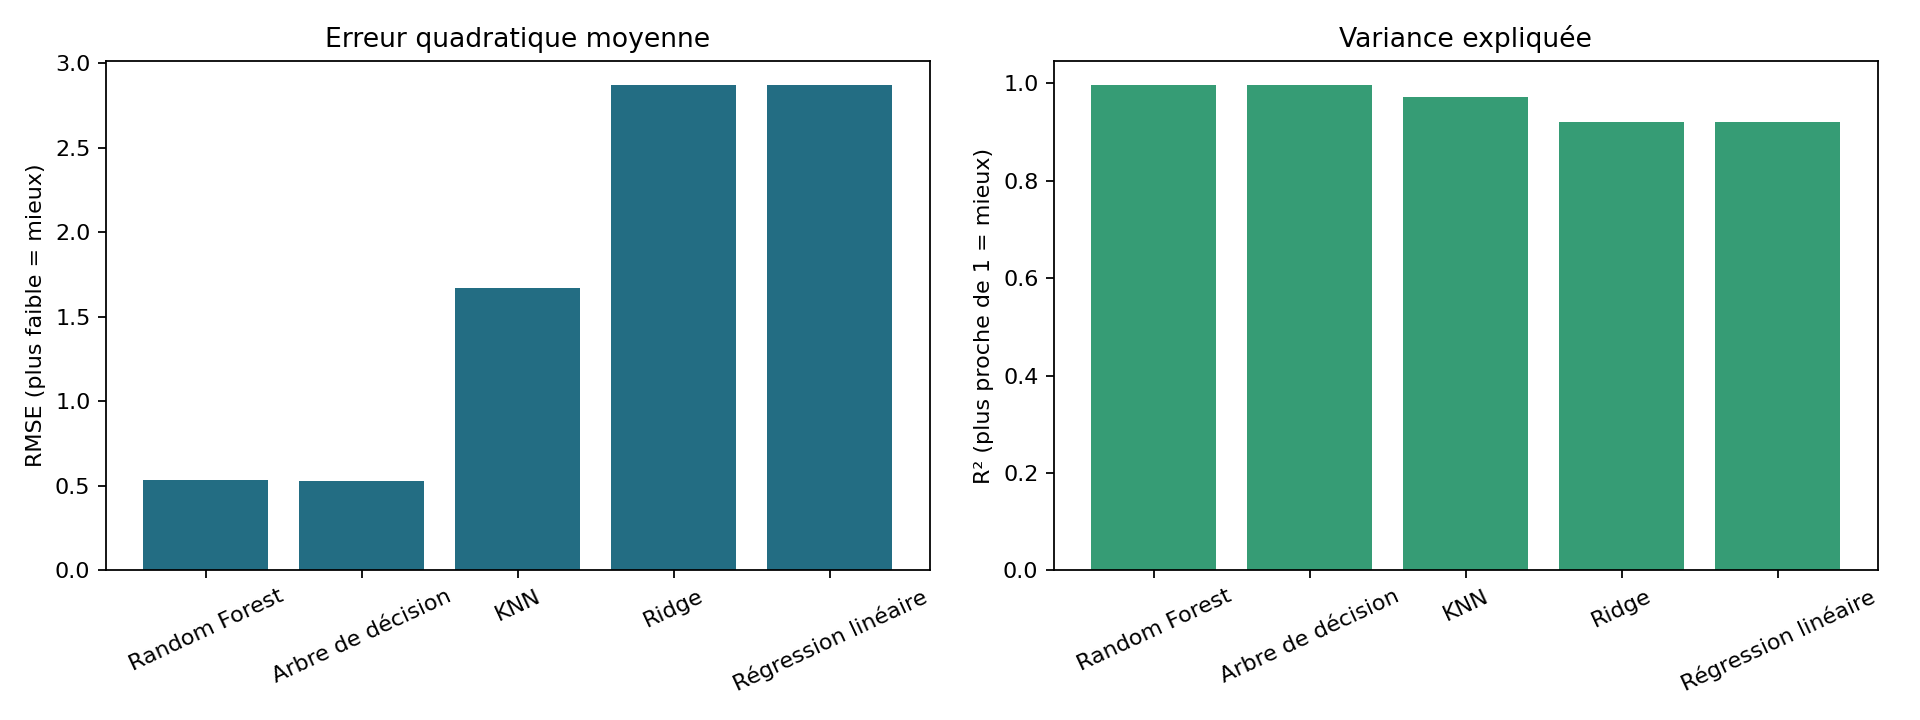

In [4]:
display(scores.round(3))
display(Image(filename=str(ROOT/'figures'/'02_comparaison.png')))

## Prédictions et résidus

Le modèle commenté est celui dont le RMSE moyen de validation croisée est le plus faible. Un résidu est `Y1 observée − Y1 prédite`. La répartition des résidus aide à voir les erreurs et les biais.

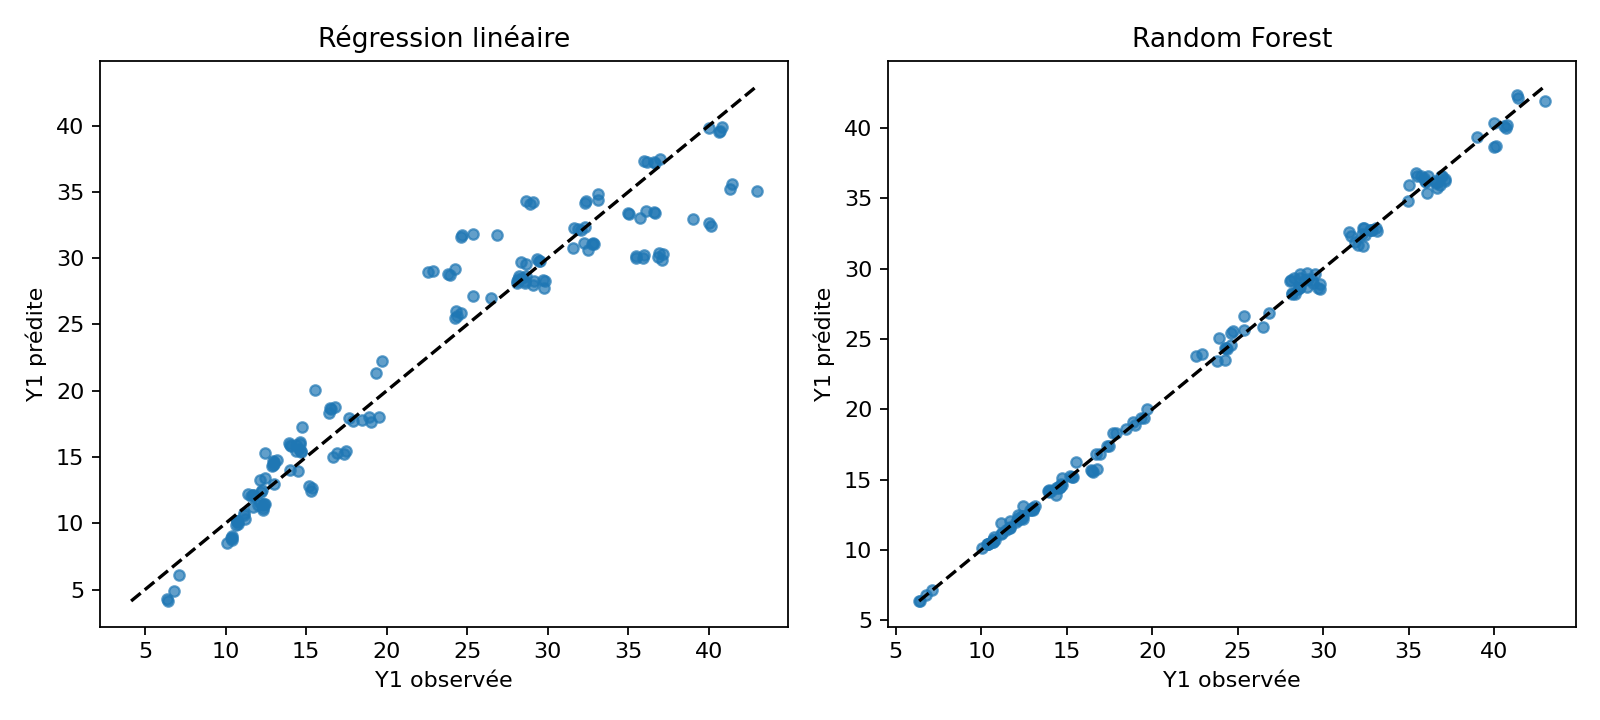

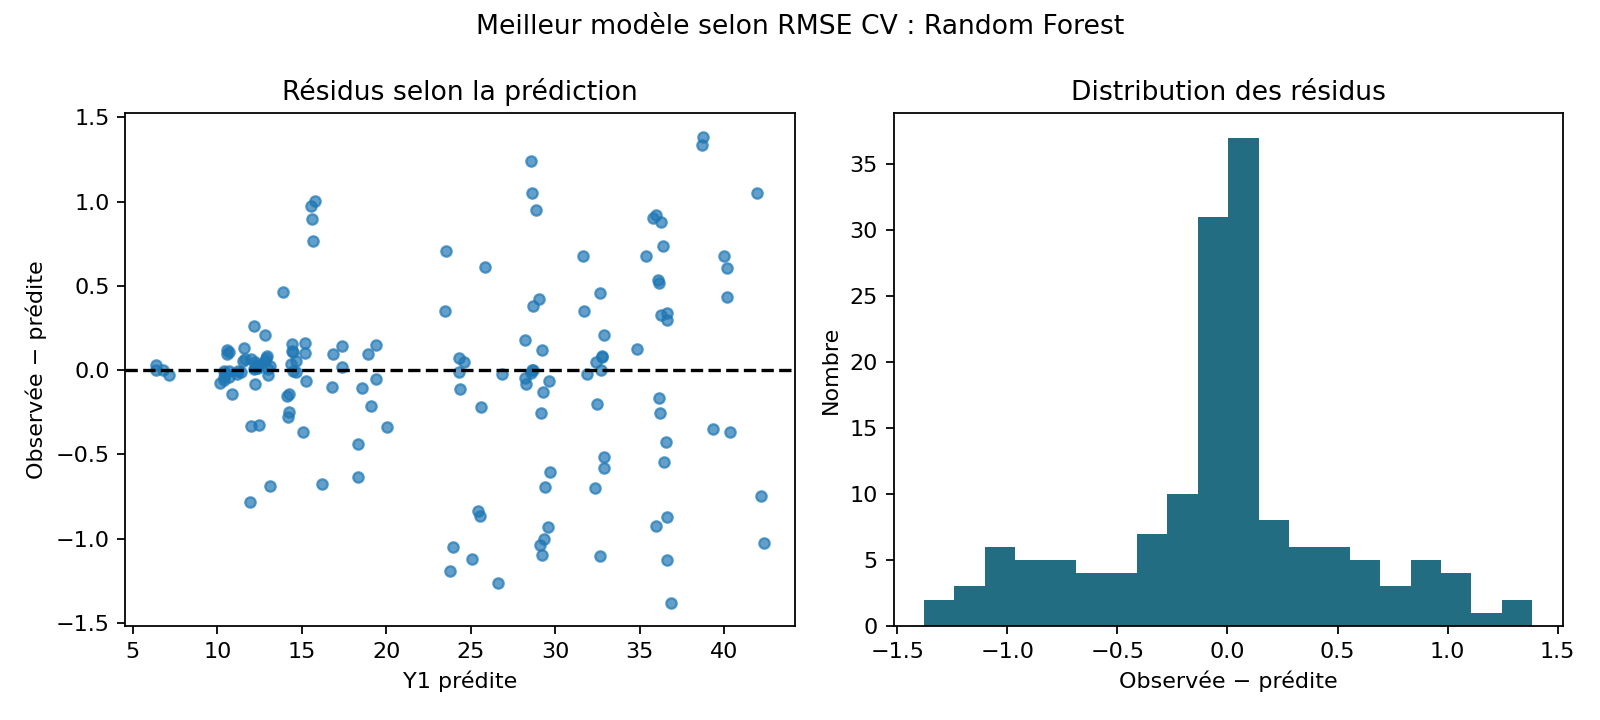

In [5]:
display(Image(filename=str(ROOT/'figures'/'03_observe_predit.png')))
display(Image(filename=str(ROOT/'figures'/'04_residus.png')))

## Erreurs selon certaines caractéristiques

Les écarts par sous-groupe sont descriptifs et reposent sur de petits effectifs pour certaines catégories. Ils ne servent pas à choisir le modèle.

In [6]:
groups = pd.read_csv(ROOT/'results'/'erreurs_par_groupe.csv')
display(groups.round(3))

,Caracteristique,Valeur,Effectif,MAE
0,X5,3.50,72,0.171
1,X5,7.00,82,0.546
2,X6,2.00,45,0.372
3,X6,3.00,33,0.289
4,X6,4.00,37,0.398
5,X6,5.00,39,0.412
6,X7,0.00,8,0.280
7,X7,0.10,51,0.418
8,X7,0.25,51,0.272
9,X7,0.40,44,0.448


## Limites

Le jeu contient des configurations simulées, et le test est une seule partition aléatoire. Les résultats ne prouvent pas la même qualité de prédiction sur des bâtiments réels. Une évaluation sur des données externes serait nécessaire avant une application pratique. Source : UCI Energy Efficiency, dataset 242.